# PYRAXIS data tour: every dataset, where it lives, and what uses it

This notebook is the map of **all the data in the project**:

- **Part A:** the four clean tables the models and dashboard are built from
- **Part B:** exactly which rows train each of the 7 models
- **Part C:** where every clean row came from (the original NASA PSI files)
- **Part D:** the model outputs and the files the dashboard reads
- **Part E:** documents (PDF reports), raw sensor logs, inventory, official resources
- **Part F:** how to add new data

Every number below is computed live from the files, so this notebook never goes out of date. **Kernel:** `Python (spaceapp)`. Run top to bottom.

### The data at a glance

| Stage | Path | What it is | Built by | Used by |
|---|---|---|---|---|
| **Inventory** | `data/inventory/` | List of all 60,826 PSI files (24 investigations, 13.5 TB), plus investigation metadata | `scripts/psi_inventory.py` | Downloads, dashboard metadata |
| **Raw PSI files** | `data/raw/` → link to **`D:/psi_raw`** | Original NASA files: experimental tables, data summaries, instrument logs, reports (~16 GB of tables, documents and logs, about 0.1 % of the archive) | `scripts/psi_download.py` | The dataset builders |
| **Clean tables** | `data/processed/*.parquet` (+ `.csv` copies) | `tests` (1 row per test), `detection` (smoke tests), `smoke_points` (SPICE), `investigations` | `pipeline/build_*.py` | Models, dashboard |
| **Models** | `data/processed/models/*.joblib` | 7 fitted models | `pipeline/train_models.py` | Notebook 02, reuse |
| **Reports** | `data/processed/model_report.json`, `layers_report.json` | Every score vs every baseline | `pipeline/train_models.py` | Write-up |
| **Dashboard data** | `dashboard/public/data/*.json`, `dashboard/data/search_chunks.json` | What the website shows; Ask-the-data passages | builders + `train_models.py` + `build_search_index.py` | Dashboard |
| **Official resources** | `data/official/` | NASA Researcher's Guide, fact sheets, Apollo/Mir/spinoff pages | saved 13 Nov | Ask the data |

**Rule of thumb:** start from the clean tables (Part A). Go back to raw files only when you need something they don't have.

In [1]:
import json, re, pathlib, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = pathlib.Path.cwd()
while not (ROOT / "pipeline").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "pipeline"))
P, RAW = ROOT / "data/processed", ROOT / "data/raw"
BLUE, ORANGE, GREEN, PINK = "#2a78d6", "#eb6834", "#1baf7a", "#c23d8f"   # same validated palette as the dashboard
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 60)
RAW_OK = RAW.exists()
print("project root:", ROOT)
print("raw data (data/raw -> D:/psi_raw) available:", RAW_OK, "" if RAW_OK else "- plug in drive D: for Parts C and E")

project root: C:\Users\USER\Desktop\Projects\nasa
raw data (data/raw -> D:/psi_raw) available: True 


## Part A: the clean tables

### A1. `tests.parquet`: one row per test, all 24 investigations

Built by `pipeline/build_tests.py`, which runs one small reader ("adapter") per investigation, all writing **the same columns in SI units**. Every row keeps `source_file` + `source_row`: the exact NASA spreadsheet row it came from.

`row_kind` tells you what a row is:
- `test`: one physical test
- `daily_summary`: one ISS test day (ACME, SLICE)
- `matrix`: a published test-plan envelope, not individual runs (FLEX-2)

In [2]:
tests = pd.read_parquet(P / "tests.parquet")
print(f"{len(tests):,} rows | {tests.accession.nunique()} investigations | by kind: {tests.row_kind.value_counts().to_dict()}")
tests.groupby("acronym").agg(rows=("test_id", "size"), kind=("row_kind", lambda s: ", ".join(sorted(s.unique()))),
                             fuel_phase=("fuel_phase", lambda s: ", ".join(sorted(s.dropna().unique()))),
                             O2_known=("o2_frac", "count"), pressure_known=("pressure_kpa", "count"),
                             outcome_known=("outcome", lambda s: int((s != "unknown").sum()))).sort_values("rows", ascending=False)

1,709 rows | 15 investigations | by kind: {'test': 1423, 'matrix': 160, 'daily_summary': 126}


,rows,kind,fuel_phase,O2_known,pressure_known,outcome_known
acronym,,,,,,
ACME CFI-G,333,test,gas,179,333,333
ACME Flame Design,327,test,gas,207,307,0
FLEX,274,test,liquid droplet,274,273,274
CFI,227,test,liquid droplet,227,227,146
FLEX-2,160,matrix,liquid droplet,160,160,0
BASS-II,129,test,solid,129,129,0
BASS,122,test,solid,121,121,113
ACME BRE,43,daily_summary,gas (emulates solid),43,0,43
ACME CLD Flame,32,daily_summary,gas,0,0,32


**What the main columns mean**

| Column | Meaning | Unit |
|---|---|---|
| `o2_frac` / `o2_pct` | Oxygen in the **surrounding air** | fraction / % |
| `burner_o2_frac` | Inverse flames only: oxygen in the **burner stream** (the surrounding air is fuel, so `o2_frac` is empty) | fraction |
| `pressure_kpa`, `o2_partial_kpa` | Total pressure; oxygen partial pressure (= O₂ fraction × pressure) | kPa |
| `pressure_assumed` | **True** = the table had no pressure, we used ISS cabin pressure (101.3 kPa). Never silently invented | flag |
| `fuel`, `fuel_phase`, `material` | What burned: liquid droplet, solid, gas | text |
| `droplet_d0_mm`, `thickness_mm`, `sample_size_cm`, `geometry` | Sample size and shape | mm / cm |
| `flow_cm_s`, `diluent` | Air speed past the sample; added inert gas (N₂, CO₂, He) | cm/s |
| `outcome` | How the test ended (`extinguished`, `disrupted`, `burned`, `no ignition`, …) | text |
| `burning_rate_mm2_s`, `extinction_d_mm`, `burn_time_s` | Measured results | mm²/s, mm, s |
| `cool_flame`, `reignitions`, `extinguished_by` | CFI cool flames; CFI re-ignitions; BASS: put out by N₂ or low flow | |
| `source_file`, `source_row` | **Provenance**: where the row came from | |

In [3]:
# Provenance in action: pick any row and see exactly where it came from
r = tests[tests.accession == "PSI-69"].iloc[0]
print(f"{r.acronym} test {r.test_id}: O2 {r.o2_pct:.1f}%, {r.pressure_kpa:.1f} kPa, K = {r.burning_rate_mm2_s} mm²/s")
print("came from:", r.source_file, "row", r.source_row)

FLEX test 20CAL08: O2 21.0%, 101.0 kPa, K = 0.52 mm²/s
came from: data/raw/PSI-69/Experimental table/PSI-69_Experimental table_FLEX.csv row 2


### A2. The coverage questions behind the headline

These are the exact filters behind *"17 tests near Moon-base air, none on solid materials"* (±5 % O₂, ±25 % pressure; inverse flames excluded because their oxygen is in the burner, not the air).

In [4]:
air = tests.dropna(subset=["o2_pct", "pressure_kpa"])
def near(o2, p):
    return air[(abs(air.o2_pct - o2) <= 5) & (abs(np.log(air.pressure_kpa / p)) <= np.log(1.25))]
moon, iss = near(34, 10.2 * 6.89476), near(21, 101.3)
solid = tests[tests.fuel_phase == "solid"]
print(f"Near Moon-base air (34% O2, 70 kPa): {len(moon)} rows -> {moon.acronym.value_counts().to_dict()} | solids: {(moon.fuel_phase=='solid').sum()}")
print(f"Near ISS air (21% O2, 101 kPa):      {len(iss)} rows | solids: {(iss.fuel_phase=='solid').sum()}")
print(f"All solid-material tests: {len(solid)} | O2 {solid.o2_pct.min():.1f}-{solid.o2_pct.max():.1f}% | pressure {solid.pressure_kpa.min():.0f}-{solid.pressure_kpa.max():.0f} kPa")
hi = air[air.o2_pct >= 30]
print(f"Tests at Moon-like oxygen (>=30%): {len(hi)} -> {hi.fuel_phase.value_counts().to_dict()}")

Near Moon-base air (34% O2, 70 kPa): 17 rows -> {'FLEX': 17} | solids: 0
Near ISS air (21% O2, 101 kPa):      576 rows | solids: 241
All solid-material tests: 262 | O2 13.6-22.7% | pressure 98-102 kPa
Tests at Moon-like oxygen (>=30%): 298 -> {'gas': 234, 'liquid droplet': 64}


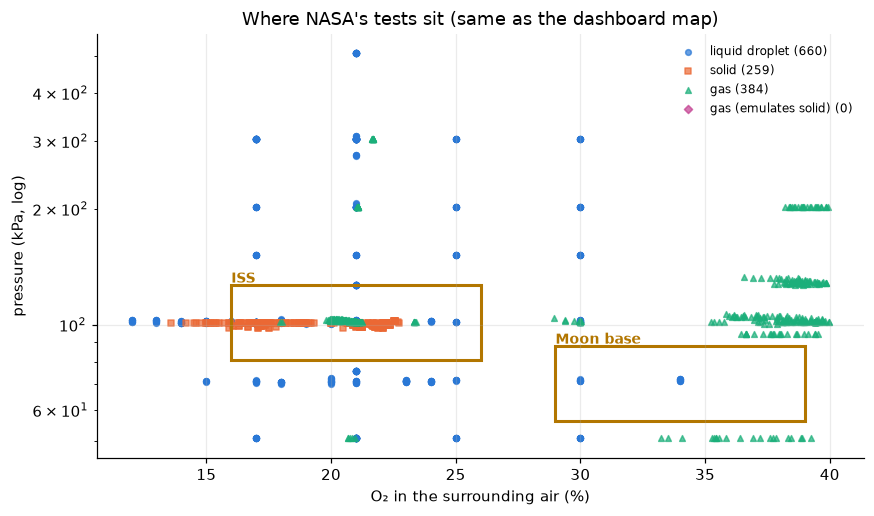

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
for ph, col, mk in [("liquid droplet", BLUE, "o"), ("solid", ORANGE, "s"), ("gas", GREEN, "^"), ("gas (emulates solid)", PINK, "D")]:
    s = air[air.fuel_phase == ph]
    ax.scatter(s.o2_pct, s.pressure_kpa, s=14, c=col, marker=mk, alpha=.7, label=f"{ph} ({len(s)})")
for (o, p, name) in [(21, 101.3, "ISS"), (34, 70.3, "Moon base")]:
    ax.add_patch(plt.Rectangle((o - 5, p / 1.25), 10, p * 1.25 - p / 1.25, fill=False, ec="#b27600", lw=2))
    ax.text(o - 5, p * 1.27, name, color="#b27600", fontsize=9, weight="bold")
ax.set_yscale("log"); ax.set(xlabel="O₂ in the surrounding air (%)", ylabel="pressure (kPa, log)", title="Where NASA's tests sit (same as the dashboard map)")
ax.legend(fontsize=8, frameon=False); plt.show()

### A3. `detection.parquet`: 120 smoke tests (Detection layer)

Built by `pipeline/build_detection.py` from the **1-second instrument logs** of SAME (PSI-102) and SAME-R (PSI-101). Per test it records:
- **baseline:** the signals *before* the sample heater switched on;
- **smoke window:** *after* it switched off;
- each detector's response, and whether it rose above 10× its baseline noise (`*_responded`);
- smoke mass (DustTrak B, mg/m³), particle count (P-Trak, per cm³) and a particle-size index;
- test conditions (heater level `heater_rt_r0`, `inlet_flow_cm_s`, `aging_s`) joined from the SAME-R experimental table.

In [6]:
det = pd.read_parquet(P / "detection.parquet")
print(f"{len(det)} smoke tests | {det.acronym.value_counts().to_dict()} | proper heater-based windows: {(det.smoke_window=='heater').sum()}")
resp = [c for c in det.columns if c.endswith("_responded")]
det.groupby("material").agg(tests=("test_no", "size"), smoke_mg_m3=("dusttrak_peak_mg_m3", "median"),
                            particles_cc=("ptrak_peak_per_cc", "median"), size_index_um=("mean_diameter_index_um", "median")).round(2).join(
    det.groupby("material")[resp].agg(lambda s: s.dropna().astype(float).mean()).round(2))

120 smoke tests | {'SAME-R': 75, 'SAME': 45} | proper heater-based windows: 104


,tests,smoke_mg_m3,particles_cc,size_index_um,iss_obscuration_responded,iss_scatter_responded,ion_a_responded,ion_b_responded,sts_responded,n_detectors_responded
material,,,,,,,,,,
Dibutyl phthalate,21,31.42,2627.0,2.89,0.90,0.90,0.29,0.62,0.00,2.71
Kapton,21,8.81,44250.0,0.71,0.38,0.86,0.38,0.90,0.29,2.62
Lampwick (cotton),17,42.17,48500.0,1.21,0.94,0.94,0.65,0.94,0.20,3.53
Pyrell (PU foam),14,88.56,56296.0,1.68,0.93,0.93,0.71,0.79,0.33,3.43
Silicone rubber,24,107.30,57572.0,1.73,0.96,0.96,0.79,0.92,0.38,3.75
Teflon,19,6.14,49100.0,0.74,0.37,0.89,0.47,0.79,0.17,2.58


### A4. `smoke_points.parquet`: SPICE smoke points (Detection layer)

Built by `pipeline/build_smoke_points.py` from the SPICE investigators' reduced flight datasheet. **Smoke point** = the flame length at which a gas flame starts to release soot; shorter = sootier. Rows with burners SPICE never flew, or zero air speed, are dropped as non-flight rows.

In [7]:
sp = pd.read_parquet(P / "smoke_points.parquet")
print(f"{len(sp)} flight flames | nozzles (mm): {sorted(sp.nozzle_mm.round(2).unique())}")
sp.groupby(["fuel", "fuel_mole_frac"]).agg(flames=("smoke_point_mm", "size"), smoke_point_mm=("smoke_point_mm", "median"),
                                             air_cm_s_min=("air_velocity_cm_s", "min"), air_cm_s_max=("air_velocity_cm_s", "max")).round(1)

70 flight flames | nozzles (mm): [np.float64(0.41), np.float64(0.76), np.float64(1.6)]


flames  smoke_point_mm  air_cm_s_min  air_cm_s_max
fuel      fuel_mole_frac                                                    
ethylene  1.00                 6            56.7          17.6          58.0
propane   1.00                 6            67.9          16.6          44.9
propylene 0.50                10            42.1          11.0          58.0
          0.75                19            29.3          12.9          64.6
          1.00                29            25.7           5.4          59.9

### A5. `investigations.parquet`: the 24 investigations (metadata)

Built by `pipeline/build_metadata.py` from PSI's investigation records: objectives, hypothesis, hardware, platform, Earth benefits, file counts.

In [8]:
inv = pd.read_parquet(P / "investigations.parquet")
inv[[c for c in ["accession", "acronym", "platform", "hardware_family", "fuel_phase", "n_files", "size_gb"] if c in inv.columns]].sort_values("accession")

,accession,acronym,platform,hardware_family,fuel_phase,n_files,size_gb
0,PSI-10,ACME/Flame Design,International Space Station (ISS),ACME modular hardware in Combustion Integrated Rack (CIR),gas,3807,2180.44
15,PSI-100,SAFFIRE-III,International Space Station (ISS),Cygnus cargo vehicle (post-ISS departure),solid,87,35.21
16,PSI-101,SAME-R,International Space Station (ISS),NaN,smoke aerosol,344,6.31
17,PSI-102,SAME,International Space Station (ISS),NaN,smoke aerosol,105,0.66
18,PSI-106,SLICE,International Space Station (ISS),SPICE flow duct in Microgravity Science Glovebox (MSG),gas,18711,60.79
19,PSI-107,SPICE,International Space Station (ISS),SPICE flow duct in Microgravity Science Glovebox (MSG),gas,188,6.95
20,PSI-115,NaN,Not Applicable,NaN,smoke aerosol,47,0.26
21,PSI-117,NaN,,NaN,liquid droplet,16,0.07
22,PSI-142,NaN,Not Applicable,NaN,liquid droplet,3,0.00
23,PSI-159,ACME CFI-G,International Space Station (ISS),ACME modular hardware in Combustion Integrated Rack (CIR),gas,3756,2085.59


## Part B: which rows train each model

The same filters `pipeline/train_models.py` uses, so the counts here match the model reports exactly.

In [9]:
import train_models as tm
drops = tm.droplet_frame(tests)
F = tm.FEATURES
bass = tests[(tests.accession == "PSI-26") & tests.outcome.isin(["burned", "no ignition", "ignited, not self-sustaining"])].dropna(subset=["o2_frac", "flow_cm_s"])
massrows = det.dropna(subset=["heater_rt_r0", "inlet_flow_cm_s", "aging_s", "dusttrak_peak_mg_m3", "material"]).query("dusttrak_peak_mg_m3 > 0")
sprows = sp.dropna(subset=["nozzle_mm", "air_velocity_cm_s", "smoke_point_mm"])
training = pd.DataFrame([
    ["Suppression", "burning_rate", "tests.parquet: FLEX (PSI-69) + CFI (PSI-39)", "burning_rate_mm2_s", len(drops.dropna(subset=F + ["burning_rate_mm2_s"]))],
    ["Suppression", "extinction_d", "tests.parquet: FLEX + CFI", "extinction_d_mm", len(drops.dropna(subset=F + ["extinction_d_mm"]))],
    ["Suppression", "outcome", "tests.parquet: FLEX only", "outcome: extinguished vs disrupted", len(drops[(drops.accession == "PSI-69") & drops.outcome.isin(["extinguished", "disrupted"])].dropna(subset=F))],
    ["Suppression", "cool_flame", "tests.parquet: CFI", "cool_flame (yes/no)", len(drops[drops.cool_flame.isin([True, False])].dropna(subset=F))],
    ["Prevention", "prevention_sustained_burn", "tests.parquet: BASS (PSI-26) as-run matrix", "outcome from crew notes: burned vs not", len(bass)],
    ["Detection", "detection_smoke_mass", "detection.parquet: SAME-R with conditions", "log10 dusttrak_peak_mg_m3", len(massrows)],
    ["Detection", "detection_smoke_point", "smoke_points.parquet: SPICE", "smoke_point_mm", len(sprows)],
], columns=["layer", "model", "training rows come from", "target", "rows"])
training

,layer,model,training rows come from,target,rows
0,Suppression,burning_rate,tests.parquet: FLEX (PSI-69) + CFI (PSI-39),burning_rate_mm2_s,405
1,Suppression,extinction_d,tests.parquet: FLEX + CFI,extinction_d_mm,340
2,Suppression,outcome,tests.parquet: FLEX only,outcome: extinguished vs disrupted,234
3,Suppression,cool_flame,tests.parquet: CFI,cool_flame (yes/no),145
4,Prevention,prevention_sustained_burn,tests.parquet: BASS (PSI-26) as-run matrix,outcome from crew notes: burned vs not,102
5,Detection,detection_smoke_mass,detection.parquet: SAME-R with conditions,log10 dusttrak_peak_mg_m3,69
6,Detection,detection_smoke_point,smoke_points.parquet: SPICE,smoke_point_mm,70


In [10]:
# The droplet training set in detail: fuels and conditions the Suppression models learn from
print("features:", F)
drops.dropna(subset=F + ["burning_rate_mm2_s"]).groupby(["accession", "fuel"]).agg(
    tests=("test_id", "size"), O2_pct=("o2_pct", lambda s: f"{s.min():.0f}-{s.max():.0f}"),
    kPa=("pressure_kpa", lambda s: f"{s.min():.0f}-{s.max():.0f}"), He=("he_frac", "max"), CO2=("co2_frac", "max"))

features: ['o2_frac', 'pressure_kpa', 'he_frac', 'co2_frac', 'droplet_d0_mm', 'fuel_carbons', 'is_alcohol', 'branched_frac']


tests O2_pct     kPa    He  CO2
accession fuel                                                            
PSI-39    n-dodecane                          74  17-21  51-507  0.59  0.0
          n-dodecane / iso-dodecane blend     74  17-21  51-507  0.59  0.0
PSI-69    Heptane                            107  13-34  70-207  0.45  0.7
          Methanol                           150  12-34  70-309  0.45  0.7

In [11]:
# The Prevention labels: how crew notes become outcomes (rules: label_bass() in pipeline/build_tests.py)
bass[["test_id", "material", "o2_pct", "flow_cm_s", "outcome", "extinguished_by", "notes"]].sample(6, random_state=2)

,test_id,material,o2_pct,flow_cm_s,outcome,extinguished_by,notes
1002,84,pmma 2 cm,21.100000,8.0,burned,low flow,"wake ign, fan pot to 0.5 (42), started getting soot ..."
949,32,1 cm sphere,20.889599,4.0,burned,burnout,"adjusted igniter, ignited at 43, he started to turn fa..."
978,61,PMMA sphere 2 cm,22.583549,10.0,burned,NaN,try blowing out the flame with GN2. blew out bottom half...
943,26,2 cm sphere,21.184054,9.0,burned,NaN,"moved sphere 1 cm downstream, readjusted igniter. Repea..."
935,19,PMMA 2 cm,21.700000,6.5,burned,low flow,bonus test. LOS partway through burn. Don instructed to...
942,25,2 cm sphere,21.184054,9.5,burned,low flow,"sphere closer to nozzle. New igniter. 1st ign, flame di..."


## Part C: where every clean row came from

Each investigation has its own reader in `pipeline/build_tests.py`. Where the experimental table wasn't enough, we read richer NASA files:

| Investigation | Extra source we read | Why |
|---|---|---|
| CFI (PSI-39) | `Science Documents/*CFI_DataSummary*.xlsx` | The investigators' own summary: burning rates, extinction sizes, cool flames for 227 tests |
| BASS (PSI-26) | `Science Documents/*As Run_Test Matrix.xlsx` | Crew observations → Prevention labels; measured O₂, pressure, CO₂ |
| SAME, SAME-R (PSI-101/102) | `Analyzed Data/*.xls` | 1-second detector and particle-counter logs |
| SPICE (PSI-107) | `Raw Data/*SmokePointReview*.xlsx` | Reduced smoke-point datasheet |
| CFI-G (PSI-159) | both experimental tables | Normal flames (O₂ in the air) and inverse flames (O₂ from the burner) handled separately |

In [12]:
src = tests.assign(file=tests.source_file.str.split("/").str[-1]).groupby(["accession", "acronym", "file"]).size().rename("rows").reset_index()
src.sort_values(["accession", "rows"], ascending=[True, False])

,accession,acronym,file,rows
1,PSI-10,ACME Flame Design,PSI-10_Experimental table_Flame Design_Normal Flame.csv,207
0,PSI-10,ACME Flame Design,PSI-10_Experimental table_Flame Design_Inverse Flame.csv,120
2,PSI-100,SAFFIRE-III,PSI-100_Experimental table_SAFFIRE-3.csv,2
3,PSI-106,SLICE,PSI-106_Experimental table_Slice.csv,12
5,PSI-159,ACME CFI-G,PSI-159_Experimental table_CFI-G_Normal Flames.csv,179
4,PSI-159,ACME CFI-G,PSI-159_Experimental table_CFI-G_Inverse Flames.csv,154
6,PSI-20,ACME BRE,PSI-20_Experimental table_ACME BRE.csv,43
7,PSI-21,ACME CLD Flame,PSI-21_Experimental table_CLD Flame.csv,32
8,PSI-22,ACME E-FIELD,PSI-22_Experimental table_ACME E-FIELD Flames.csv,21
9,PSI-23,ACME s-Flame,PSI-23_Experimental table_ACME s-Flame.csv,18


In [13]:
# Quirks the cleaner handles - examples straight from PSI's files (needs drive D:)
if RAW_OK:
    bre = pd.read_csv(next(RAW.glob("PSI-20/Experimental table/*.csv")), encoding="latin1")
    print("BRE oxygen column ('3400%' = Excel formatting of 34):", bre.iloc[:, 5].tolist()[:9])
    flex_raw = pd.read_csv(next(RAW.glob("PSI-69/Experimental table/*.csv")), encoding="latin1")
    print("FLEX pressure is in mmHg; one row has 0 mmHg (data-entry error, set to empty):", sorted(pd.to_numeric(flex_raw.filter(like="ressure").iloc[:, 0], errors="coerce").dropna().unique())[:4])
    print("FLEX raw columns:", list(flex_raw.columns)[:12], "...")

BRE oxygen column ('3400%' = Excel formatting of 34): ['21; 26.5; 40', '26.5; 34', '21; 26.5; 34; 40', '26.5; 40', '3400%', '26.5; 34', '26.5; 34', '2100%', '21; 26.5; 34']
FLEX pressure is in mmHg; one row has 0 mmHg (data-entry error, set to empty): [np.float64(0.0), np.float64(526.3), np.float64(527.6), np.float64(527.9)]
FLEX raw columns: ['FLEX Test #', 'FLEX Identifier', 'Test Date', 'Test GMT', 'Fuel', 'Ambient pressure; mmHg', 'O initial ambient composition; mole fraction', 'N initial ambient composition; mole fraction', 'CO initial ambient composition; mole fraction', 'He initial ambient composition; mole fraction', 'Droplet initial diameter; mm', 'Visible flame extinction diameter; mm'] ...


## Part D: what the models produce, and what the dashboard reads

`python pipeline/train_models.py` trains all 7 models and writes:
- **`data/processed/models/<name>.joblib`**: the fitted models, reusable in Python without retraining;
- **`model_report.json` / `layers_report.json`**: every score next to every baseline;
- **`dashboard/public/data/model.json` and `layers.json`**: the predictions the dashboard shows. The website never runs Python; it reads these files.

In [14]:
import joblib
rows = []
for f in sorted((P / "models").glob("*.joblib")):
    rows.append({"model file": f.name, "KB": round(f.stat().st_size / 1e3)})
display(pd.DataFrame(rows))
dash = ROOT / "dashboard/public/data"
pd.DataFrame([{"dashboard file": f.name, "KB": round(f.stat().st_size / 1e3)} for f in sorted(dash.glob("*.json"))] +
             [{"dashboard file": "../data/search_chunks.json (Ask the data)", "KB": round((ROOT / "dashboard/data/search_chunks.json").stat().st_size / 1e3)}])

,model file,KB
0,burning_rate.joblib,1352
1,cool_flame.joblib,190
2,detection_smoke_mass.joblib,51
3,detection_smoke_point.joblib,51
4,extinction_d.joblib,960
5,outcome.joblib,468
6,prevention_sustained_burn.joblib,105


,dashboard file,KB
0,detection.json,104
1,investigations.json,163
2,layers.json,45
3,model.json,35
4,smoke_points.json,35
5,tests.json,1857
6,../data/search_chunks.json (Ask the data),6083


In [15]:
# Use a saved model directly: burning rate of a 2 mm methanol droplet in Moon-base air, with its 95% range
m = joblib.load(P / "models/burning_rate.joblib")
x = np.array([[0.34, 70.3, 0.0, 0.0, 2.0, 1, 1, 0.0]])   # o2_frac, kPa, He, CO2, d0 mm, fuel carbons, alcohol, branched
mu, sd = m.predict(x, return_std=True)
print(f"K = {mu[0]:.3f} ± {1.96 * sd[0]:.3f} mm²/s (95% range)")

K = 0.681 ± 0.193 mm²/s (95% range)


## Part E: documents, raw sensor logs, inventory and official resources

### E1. Documents (reports, papers, presentations)

About 1,350 PDFs plus Word and PowerPoint files. They hold the context the tables lack. *Ask the data* searches them (`pipeline/build_search_index.py`). Below: list an investigation's documents, read one, and search them all for a keyword. Needs drive D:.

In [16]:
def docs(acc, cats=("Science Documents", "Reports", "Presentations", "Analyzed Data", "Engineering Documents")):
    out = []
    for c in cats:
        for f in (RAW / acc / c).glob("*"):
            out.append({"category": c, "file": f.name, "MB": round(f.stat().st_size / 1e6, 2)})
    return pd.DataFrame(out)

docs("PSI-25") if RAW_OK else "plug in drive D:"   # BASS-II

,category,file,MB
0,Science Documents,PSI-25_Science Documents_BASS-II_ReadMe.docx,0.02
1,Science Documents,PSI-25_Science Documents_BASS-II_SRD.pdf,1.11
2,Science Documents,PSI-25_Science Documents_BASS-II_Test.Matrices.xlsx,0.03
3,Reports,PSI-25_Reports_BASS-II Summary Report.pdf,48.97
4,Engineering Documents,PSI-25_Engineering Documents_BASS-II_Engineering Require...,1.12
5,Engineering Documents,PSI-25_Engineering Documents_BASS-II_Ops.docx,1.11


In [17]:
from pypdf import PdfReader
def pdf_text(path, pages=2):
    r = PdfReader(str(path)); return "\n".join((p.extract_text() or "") for p in r.pages[:pages])

def search_pdfs(acc, pattern, max_files=40, pages=3):
    hits = []
    for f in list((RAW / acc).rglob("*.pdf"))[:max_files]:
        try: txt = pdf_text(f, pages)
        except Exception: continue
        for m_ in re.finditer(pattern, txt, re.I):
            hits.append({"file": f.name[:70], "context": txt[max(0, m_.start() - 80):m_.end() + 80].replace("\n", " ")})
    return pd.DataFrame(hits)

search_pdfs("PSI-25", r"\d+(\.\d+)?\s?% ?O2|oxygen concentration").head(6) if RAW_OK else "plug in drive D:"

""


### E2. Raw sensor logs: the d²-law check

FLEX `DropletData.txt` files hold droplet diameter over time. Combustion theory (the *d²-law*) says diameter² falls linearly in time, and the slope is the **burning-rate constant K**. Below we recompute K from the raw signal and compare it with PSI's table. If they agree, the table can be trusted. *(These files use old Mac line endings `\r`.)*

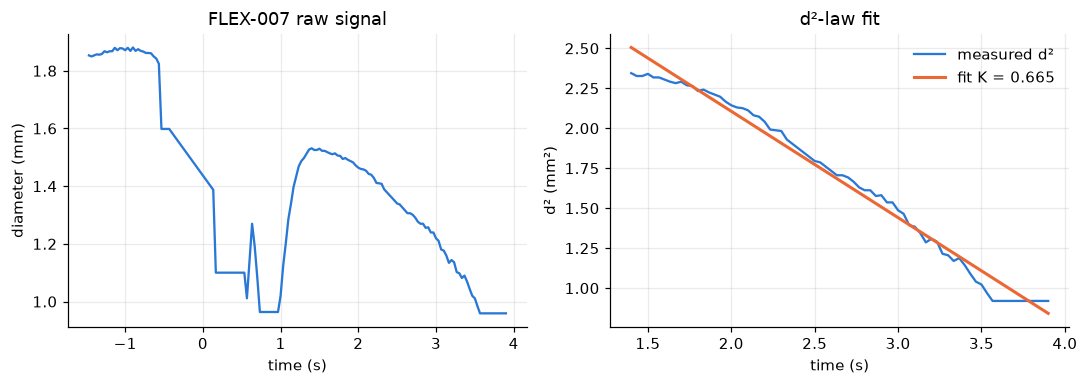

K from raw signal: 0.665 mm²/s  |  K in PSI table: [0.67]


In [18]:
def read_droplet(path):
    txt = pathlib.Path(path).read_text(errors="ignore").replace("\r\n", "\n").replace("\r", "\n")
    rows_ = [l.split("\t") for l in txt.split("\n") if l.strip()]
    df = pd.DataFrame(rows_[1:]).iloc[:, :2].apply(pd.to_numeric, errors="coerce")
    df.columns = ["t_s", "d_mm"]
    return df.dropna()

f = RAW / "PSI-69/Raw Data/PSI-69_Raw Data_FLEX-007_DropletData.txt"
if RAW_OK and f.exists():
    drop = read_droplet(f)
    burn = drop[drop.t_s > 0.5]; burn = burn.loc[burn.d_mm.idxmax():]
    K, b = np.polyfit(burn.t_s, burn.d_mm ** 2, 1); K = -K
    flex_raw = pd.read_csv(next(RAW.glob("PSI-69/Experimental table/*.csv")), encoding="latin1")
    table_K = flex_raw.loc[flex_raw["FLEX Test #"] == 7, "Burning rate; mm"].values
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    ax[0].plot(drop.t_s, drop.d_mm, color=BLUE); ax[0].set(xlabel="time (s)", ylabel="diameter (mm)", title="FLEX-007 raw signal")
    ax[1].plot(burn.t_s, burn.d_mm ** 2, color=BLUE, label="measured d²"); ax[1].plot(burn.t_s, -K * burn.t_s + b, color=ORANGE, lw=2, label=f"fit K = {K:.3f}")
    ax[1].set(xlabel="time (s)", ylabel="d² (mm²)", title="d²-law fit"); ax[1].legend(frameon=False); plt.tight_layout(); plt.show()
    print(f"K from raw signal: {K:.3f} mm²/s  |  K in PSI table: {table_K}")
else:
    print("plug in drive D: to run the raw-signal check")

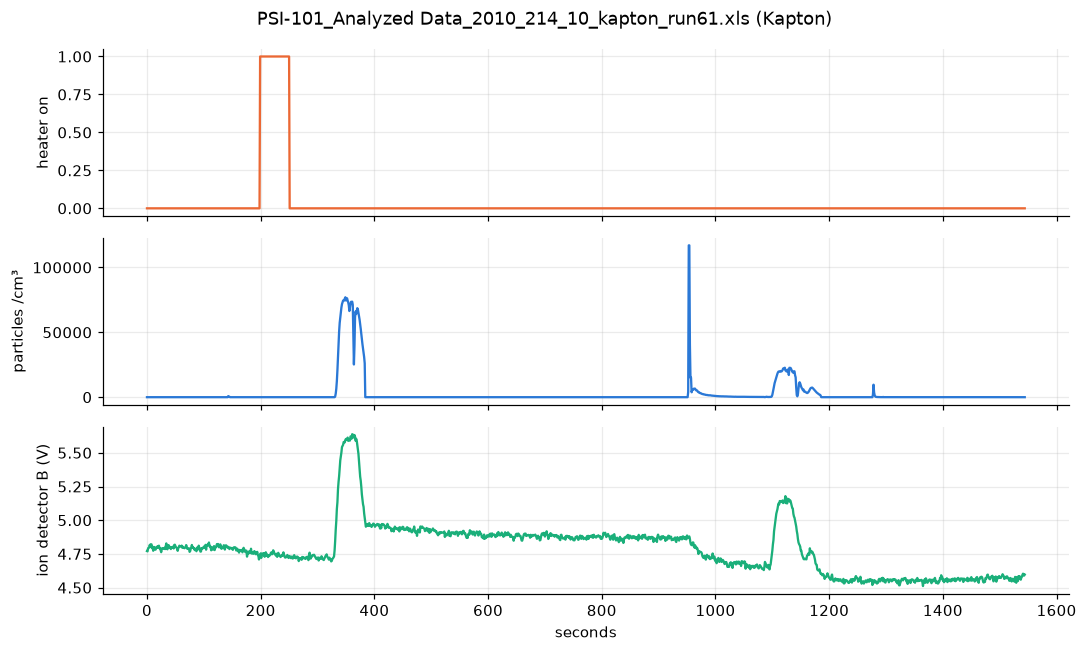

In [19]:
# One SAME-R smoke test, second by second: heater on -> smoke reaches the detectors
f = next(iter(sorted(RAW.glob("PSI-101/Analyzed Data/*run61.xls"))), None) if RAW_OK else None
if f is not None:
    d = pd.read_excel(f, sheet_name="Original (cut and paste)"); d = d[d.TestNumber > 0].reset_index(drop=True)
    t = d["ElapsedTestTime(Secs)"].index
    fig, ax = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
    ax[0].plot(t, d["HeatingInProgress"], color=ORANGE); ax[0].set_ylabel("heater on")
    ax[1].plot(t, d["PTrakMeasurement(PtPerCC)"].clip(lower=0), color=BLUE); ax[1].set_ylabel("particles /cm³")
    ax[2].plot(t, d["IonDetectorBMeasurement(Volts)"], color=GREEN); ax[2].set_ylabel("ion detector B (V)"); ax[2].set_xlabel("seconds")
    fig.suptitle(f"{f.name} (Kapton)"); plt.tight_layout(); plt.show()

### E3. The inventory: every file PSI holds

In [20]:
files = pd.read_csv(ROOT / "data/inventory/files.csv").drop_duplicates("key")
print(f"{len(files):,} files, {files.bytes.sum() / 1e12:.1f} TB across {files.accession.nunique()} investigations")
files.groupby("category").agg(files=("key", "size"), GB=("bytes", lambda b: round(b.sum() / 1e9, 1))).sort_values("GB", ascending=False).head(10)

60,826 files, 13.5 TB across 24 investigations


,files,GB
category,,
Raw Data,59883,13457.2
Calibration,183,9.9
Presentations,102,1.3
Reference Data,59,1.1
Analyzed Data,248,1.0
Engineering Documents,185,1.0
Science Documents,80,0.2
Reports,31,0.1
Investigation Metadata Files,24,0.0


### E4. NASA's official challenge resources (`data/official/`)

The Researcher's Guide to ISS Combustion Science, 8 fact sheets, and the Apollo 1 / Apollo 13 / Mir fire and spinoff pages. All are indexed for *Ask the data*. Links are in `data/official/LINKS.md`.

In [21]:
off = ROOT / "data/official"
pd.DataFrame([{"file": str(f.relative_to(off)), "KB": round(f.stat().st_size / 1e3)} for f in sorted(off.rglob("*")) if f.is_file()])

,file,KB
0,LINKS.md,3
1,pages\apollo_13_lessons_learned.txt,16
2,pages\apollo_1_lessons_learned.txt,16
3,pages\mir_fire_1997.txt,6
4,pages\nasa_combustion_science_overview.txt,10
5,pages\researchers_guide_landing_page.txt,2
6,pages\spinoff_fire_attire.txt,3
7,pages\spinoff_fire_detector.txt,2
8,pages\spinoff_firemans_air_tanks.txt,2
9,pdfs\factsheet_advanced-combustion-via-microgravity-expe...,851


## Part F: adding new data

1. **New table format?** Write or extend a reader ("adapter") in `pipeline/build_tests.py`: one function per investigation, same columns, and always keep `source_file` / `source_row`.
2. **Re-run the pipeline** (drive D: connected):
```
python pipeline/build_metadata.py
python pipeline/build_tests.py
python pipeline/build_detection.py      # ~10 min
python pipeline/build_smoke_points.py
python pipeline/train_models.py         # ~4 min
python pipeline/build_search_index.py   # ~4 min
```
3. Re-run this notebook and `02_train_models.ipynb` to check the numbers.
4. The dashboard reads `dashboard/public/data/*.json` and updates on refresh.